# PMRT: module ablation, feature distributions, confusion matrices and ROC curves (Kaggle or Colab)

One notebook for everything:
1. trains the model **without** one module (`ABLATE`) with exactly the settings of the final run (resumable),
2. compares test metrics with vs without the module,
3. extracts the intermediate features of both models on the test subjects: t-SNE, class distributions along the discriminant axis, separability metrics,
4. draws confusion matrices and ROC curves of the final model (and ROC with vs without the module).

`ABLATE = "physe"`: Phy-SE blocks replaced by plain ResNet blocks (no SE at all). `ABLATE = "stdse"`: Phy-SE blocks replaced by standard SE-ResNet blocks (Fig. 3 of the reference paper, adapted to 1-D): isolates the derivative path and the dual-path attention of Fig. 4. `ABLATE = "fusion"`: Cross-Modal Fusion replaced by concatenation + 1x1 convolution. `ABLATE = "singleconv"`: both ResNet feature extractors replaced by a stem followed by one plain convolution per stage (no residual block, no second convolution, no attention); everything else (fusion, FPN, Transformer, heads) is unchanged. `ABLATE = "oneconv"`: each branch has exactly one learned convolution layer (the stem convolution with kernel 7 and 64 channels); the following stages only apply fixed average pooling to its output, so the four multi-scale feature maps all have 64 channels and the three Cross-Modal Fusion modules take 64 input channels; the rest of the model is unchanged.

**Kaggle:** Accelerator GPU T4, Internet On, then Save Version > Save & Run All (Commit). The data zip sharing must be "Anyone with the link" while it downloads. Steps 2-4 need the finished run `pmrt_mt3_cv5` (test predictions and checkpoints). If they are not found, the notebook trains the ablated model, saves `ablation_run_<ABLATE>.zip` and skips 2-4: download that zip, unzip it into `sleep_project/runs/` on Google Drive and run this notebook in Colab (training is skipped there, only steps 2-4 run).
**Colab:** needs `sleep_project` on Google Drive with `runs/pmrt_mt3_cv5`. Upload `ablation_run_<ABLATE>.zip` into `sleep_project` (next to `folds_5.json`); the notebook unzips it into `runs/` by itself. Runtime: GPU.

In [1]:
# Environment: Kaggle (data downloaded from the shared Drive zip) or Google Colab (data on Google Drive)
import os, sys, glob, shutil, subprocess, zipfile, time
from pathlib import Path
KAGGLE = os.path.exists("/kaggle/working")
FILE_ID = "11VPVORnZ951jWSle1wMWC0DAuLz5aFC-"
T_START, TIME_LIMIT_H = time.time(), 10.5
if KAGGLE:
    ROOT = Path("/kaggle/working")
    hits = sorted(glob.glob("/kaggle/input/**/x.npy", recursive=True))
    if not hits:
        tmp = Path("/tmp/capdata")
        if not list(tmp.rglob("x.npy")):
            try:
                import gdown
            except ImportError:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True); import gdown
            tmp.mkdir(parents=True, exist_ok=True)
            gdown.download(id=FILE_ID, output="/tmp/cap.zip", quiet=False)
            zipfile.ZipFile("/tmp/cap.zip").extractall(tmp); os.remove("/tmp/cap.zip")
        hits = sorted(str(p) for p in tmp.rglob("x.npy"))
    assert hits, "x.npy not found in the zip / Kaggle input"
    DATA = Path(hits[0]).parent
    folds = sorted(glob.glob(str(DATA / "folds_5.json")) + glob.glob("/tmp/capdata/**/folds_5.json", recursive=True)
                   + glob.glob("/kaggle/input/**/folds_5.json", recursive=True))
    assert folds, "folds_5.json not found"
    FOLDS_FILE = Path(folds[0])
    for prev in glob.glob("/kaggle/input/**/pmrt_mt3_no_*_cv5", recursive=True):
        shutil.copytree(prev, ROOT / "runs" / Path(prev).name, dirs_exist_ok=True)
        print("previous Kaggle output found and copied:", prev)
else:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    ROOT = Path("/content/drive/MyDrive/sleep_project")
    DATA, FOLDS_FILE = ROOT / "cap_dataset_cache", ROOT / "folds_5.json"
    for name in ("physe", "stdse", "fusion", "singleconv", "oneconv"):
        z = ROOT / f"ablation_run_{name}.zip"
        if z.exists() and not (ROOT / "runs" / f"pmrt_mt3_no_{name}_cv5" / "fold4" / "best_dis.pt").exists():
            zipfile.ZipFile(z).extractall(ROOT / "runs")
            print("ablated model unzipped from", z)
print("platform:", "Kaggle" if KAGGLE else "Colab", "| data:", DATA, "| folds:", FOLDS_FILE, "| outputs:", ROOT)
print("files in data folder:", sorted(os.listdir(DATA)))

Mounted at /content/drive
ablated model unzipped from /content/drive/MyDrive/sleep_project/ablation_run_oneconv.zip
platform: Colab | data: /content/drive/MyDrive/sleep_project/cap_dataset_cache | folds: /content/drive/MyDrive/sleep_project/folds_5.json | outputs: /content/drive/MyDrive/sleep_project
files in data folder: ['index.csv', 'x.npy']


In [2]:
# Model module of the final run (pmrt_mt3.py), written next to the notebook
import base64
from pathlib import Path
Path(ROOT, "pmrt_mt3.py").write_bytes(base64.b64decode("..."))
print("pmrt_mt3.py written to", ROOT)


pmrt_mt3.py written to /content/drive/MyDrive/sleep_project


In [3]:
# Settings (training settings identical to the final run pmrt_mt3_cv5) (ABLATE: physe = plain ResNet block, stdse = standard SE-ResNet block, fusion = concat + 1x1 conv, singleconv = one convolution per stage, oneconv = one convolution layer per branch)
ABLATE = "oneconv"
FOLDS = [0, 1, 2, 3, 4]
N_FOLDS = 5
SEQ_LEN = 12
EPOCHS, PATIENCE, MIN_EPOCHS = 60, 12, 15
BATCH_SEQ, LR, WD = 24, 5e-4, 0.05
PER_SUBJECT = 1500
EMA_DECAY = 0.999
SEED = 42
FEATURE_FRACTION = 0.2
MAX_POINTS_PER_CLASS = 1500


In [4]:
# Libraries, device, paths and figure style
import json, importlib, warnings, shutil
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
sys.path.insert(0, str(ROOT))
import pmrt_mt3 as M
importlib.reload(M)
assert ABLATE in ("physe", "stdse", "fusion", "singleconv", "oneconv")
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "- WARNING: no GPU")
LABEL = {None: "With module (final model)", "physe": "Without Phy-SE (plain ResNet block)", "stdse": "Phy-SE replaced by standard SE-ResNet block", "fusion": "Without Cross-Modal Fusion (concat + 1x1 conv)",
         "singleconv": "Single convolution per stage (no ResNet block)",
         "oneconv": "One convolution layer per branch (stem only, fixed pooling after it)"}
ABL = ROOT / "runs" / f"pmrt_mt3_no_{ABLATE}_cv5"
OUT = ROOT / f"ablation_analysis_{ABLATE}"
shutil.rmtree(OUT, ignore_errors=True); OUT.mkdir(parents=True)
cands = [ROOT / "runs" / "pmrt_mt3_cv5", Path(DATA) / "runs" / "pmrt_mt3_cv5"] + [Path(p) for p in glob.glob("/kaggle/input/**/pmrt_mt3_cv5", recursive=True) + glob.glob("/tmp/capdata/**/pmrt_mt3_cv5", recursive=True)]
def _ok(c, ck=False): return all((c / f"fold{k}" / n).exists() for k in FOLDS for n in (("test_pred.csv", "best_stress.pt", "best_dis.pt") if ck else ("test_pred.csv",)))
MAIN = next((c for c in cands if _ok(c, True)), None) or next((c for c in cands if _ok(c)), cands[0])
if not _ok(ABL):
    for p in glob.glob("/kaggle/input/**/pmrt_mt3_no_" + ABLATE + "_cv5", recursive=True) + glob.glob("/tmp/capdata/**/pmrt_mt3_no_" + ABLATE + "_cv5", recursive=True):
        if _ok(Path(p)): shutil.copytree(p, ABL, dirs_exist_ok=True); print("ablated model restored from", p); break
print("final run folder:", MAIN, "| predictions:", _ok(MAIN), "| checkpoints:", _ok(MAIN, True), "| ablated model complete:", _ok(ABL), "| ablated checkpoints:", _ok(ABL, True))
NAVY, SLATE = "#1d4e89", "#8c99a6"
CLS = ["#1d4e89", "#3f8f8a", "#d39a4f", "#9b8fae", "#b5546b", "#6f8f7e"]
plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})


device: cuda Tesla T4
final run folder: /content/drive/MyDrive/sleep_project/runs/pmrt_mt3_cv5 | predictions: True | checkpoints: True | ablated model complete: True | ablated checkpoints: True


In [5]:
# Ablated model variants (same tensor shapes as the original model)
class PlainBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=2):
        super().__init__()
        self.main = nn.Sequential(nn.Conv1d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm1d(c_out), nn.ReLU(inplace=True),
                                  nn.Conv1d(c_out, c_out, 3, 1, 1, bias=False), nn.BatchNorm1d(c_out))
        self.short = nn.Sequential(nn.Conv1d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm1d(c_out))
        self.act = nn.ReLU(inplace=True)
    def forward(self, x): return self.act(self.main(x) + self.short(x))

class PlainResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256, 512)):
        super().__init__()
        self.stem = M.StemBlock(widths[0])
        c, st = widths[0], []
        for w in widths: st.append(PlainBlock(c, w)); c = w
        self.stages = nn.ModuleList(st)
    def forward(self, x):
        x, feats = self.stem(x), []
        for s in self.stages: x = s(x); feats.append(x)
        return feats

class StdSEBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=2, r=16):
        super().__init__()
        self.main = nn.Sequential(nn.Conv1d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm1d(c_out), nn.ReLU(inplace=True),
                                  nn.Conv1d(c_out, c_out, 3, 1, 1, bias=False), nn.BatchNorm1d(c_out))
        h = max(c_out // r, 4)
        self.se1, self.se2 = nn.Linear(c_out, h), nn.Linear(h, c_out)
        self.short = nn.Sequential(nn.Conv1d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm1d(c_out))
        self.act = nn.ReLU(inplace=True)
    def forward(self, x):
        fm = self.main(x)
        s = torch.sigmoid(self.se2(F.relu(self.se1(fm.mean(-1))))).unsqueeze(-1)
        return self.act(fm * s + self.short(x))

class StdSEResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256, 512)):
        super().__init__()
        self.stem = M.StemBlock(widths[0])
        c, st = widths[0], []
        for w in widths: st.append(StdSEBlock(c, w)); c = w
        self.stages = nn.ModuleList(st)
    def forward(self, x):
        x, feats = self.stem(x), []
        for s in self.stages: x = s(x); feats.append(x)
        return feats

class SingleConvNet(nn.Module):
    def __init__(self, widths=(64, 128, 256, 512)):
        super().__init__()
        self.stem = M.StemBlock(widths[0])
        c, st = widths[0], []
        for w in widths:
            st.append(nn.Sequential(nn.Conv1d(c, w, 3, 2, 1, bias=False), nn.BatchNorm1d(w), nn.ReLU(inplace=True))); c = w
        self.stages = nn.ModuleList(st)
    def forward(self, x):
        x, feats = self.stem(x), []
        for s in self.stages: x = s(x); feats.append(x)
        return feats

class OneConvNet(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        self.stem = M.StemBlock(width)
        self.pool = nn.AvgPool1d(3, 2, 1)
    def forward(self, x):
        x, feats = self.stem(x), []
        for _ in range(4):
            x = self.pool(x); feats.append(x)
        return feats

class PlainFusion(nn.Module):
    def __init__(self, c_in, d=128):
        super().__init__()
        self.pa = nn.Sequential(nn.Conv1d(c_in, d, 1, bias=False), nn.BatchNorm1d(d))
        self.pb = nn.Sequential(nn.Conv1d(c_in, d, 1, bias=False), nn.BatchNorm1d(d))
        self.out = nn.Sequential(nn.Conv1d(2 * d, d, 1, bias=False), nn.BatchNorm1d(d), nn.ReLU(inplace=True))
    def forward(self, fa, fb): return self.out(torch.cat([self.pa(fa), self.pb(fb)], 1))

def build_model(ablate=None):
    m = M.PMRTTemporal(L=SEQ_LEN, stage_head=True)
    if ablate == "physe": m.branch_eeg, m.branch_emg = PlainResNet(), PlainResNet()
    if ablate == "stdse": m.branch_eeg, m.branch_emg = StdSEResNet(), StdSEResNet()
    if ablate == "singleconv": m.branch_eeg, m.branch_emg = SingleConvNet(), SingleConvNet()
    if ablate == "oneconv":
        m.branch_eeg, m.branch_emg = OneConvNet(), OneConvNet()
        m.fusion = nn.ModuleList([M.CrossModalFusion(64, 128, 16) for _ in range(3)])
    if ablate == "fusion": m.fusion = nn.ModuleList([PlainFusion(c) for c in (128, 256, 512)])
    return m.to(DEV)

for tag, a in (("with module", None), (ABLATE, ABLATE)):
    n = sum(p.numel() for p in build_model(a).parameters())
    print(f"{tag:12s}: {n / 1e6:.2f} M parameters")

with module : 9.96 M parameters
oneconv     : 0.85 M parameters


In [6]:
# Data and the same subject-wise folds as the final run
X, idx = M.load_data(str(DATA))
REC = idx.record.to_numpy()
FOLD = json.loads(FOLDS_FILE.read_text())
DIS, STG = idx.dis.to_numpy(np.int64), idx.stg.to_numpy(np.int64)
print("windows:", X.shape, "| subjects:", idx.record.nunique())

windows: (483170, 2, 625) | subjects: 103


In [7]:
# Train the model without the module: same folds, losses, optimiser and early stopping as the final run
ABL.mkdir(parents=True, exist_ok=True)
(ABL / "config.json").write_text(json.dumps({k: globals()[k] for k in ["N_FOLDS", "SEQ_LEN", "EPOCHS", "PATIENCE", "MIN_EPOCHS", "BATCH_SEQ", "LR", "WD", "PER_SUBJECT", "EMA_DECAY", "SEED"]} | {"ablate": ABLATE}, indent=1))
for k in FOLDS:
    fdir = ABL / f"fold{k}"
    if (fdir / "test_pred.csv").exists():
        print(f"fold {k}: already finished - skipped"); continue
    if time.time() - T_START > TIME_LIMIT_H * 3600:
        print(f"time limit reached before fold {k} - run again to continue"); break
    torch.manual_seed(SEED + k); np.random.seed(SEED + k)
    rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
    tg = M.Targets(idx, rows["train"])
    yz = tg.encode()
    Y = {"hr": yz[:, 0], "rmssd": yz[:, 1], "dis": DIS, "stg": STG}
    tr = M.SequenceBatches(X, Y, idx, rows["train"], BATCH_SEQ, DEV, SEQ_LEN, PER_SUBJECT, train=True)
    va = M.SequenceBatches(X, Y, idx, rows["val"], 64, DEV, SEQ_LEN, train=False)
    te = M.SequenceBatches(X, Y, idx, rows["test"], 64, DEV, SEQ_LEN, train=False)
    print(f"\n===== fold {k} | train {len(np.unique(REC[rows['train']]))} subj | val {len(np.unique(REC[rows['val']]))} | test {len(np.unique(REC[rows['test']]))} =====")
    loss_fn = M.MultiTaskLoss(idx.iloc[rows["train"]], DEV)
    model = build_model(ABLATE)
    M.train_fold(model, tr, va, loss_fn, tg, DIS, STG, REC, fdir, epochs=EPOCHS, lr=LR, wd=WD,
                 patience=PATIENCE, min_epochs=MIN_EPOCHS, use_aug=True, ema_decay=EMA_DECAY)
    model.load_state_dict(torch.load(fdir / "best_stress.pt", map_location=DEV, weights_only=False)["model"])
    j, p = M.predict(model, te)
    model.load_state_dict(torch.load(fdir / "best_dis.pt", map_location=DEV, weights_only=False)["model"])
    j2, p2 = M.predict(model, te)
    assert (j == j2).all() and (j == np.sort(rows["test"])).all()
    out = idx.iloc[j][["record", "group", "stage", "clipped", "dis", "stg"] + M.REG].reset_index(drop=True)
    out["fold"] = k
    out["hr_pred"], out["rmssd_pred"] = tg.decode(p["hr"], p["rmssd"])
    for c, name in enumerate(M.DISORDERS): out[f"p_{name}"] = p2["dis"][:, c]
    for c, name in enumerate(M.STAGES): out[f"p_{name}"] = p["stg"][:, c]
    out["mu_hr"], out["mu_rmssd"] = np.median(tg.raw[rows["train"]], 0)
    out.to_csv(fdir / "test_pred.csv", index=False)
    (fdir / "last.pt").unlink(missing_ok=True)
    print(f"fold {k} saved")
print("\ntraining finished")

fold 0: already finished - skipped
fold 1: already finished - skipped
fold 2: already finished - skipped
fold 3: already finished - skipped
fold 4: already finished - skipped

training finished


In [8]:
# Package the trained model without the module and decide which analysis steps can run
done = [k for k in FOLDS if (ABL / f"fold{k}" / "test_pred.csv").exists()]
print("finished folds of the ablated model:", done, "of", FOLDS)
zip_run = shutil.make_archive(str(ROOT / f"ablation_run_{ABLATE}"), "zip", ROOT / "runs", ABL.name)
print("saved", zip_run, f"({Path(zip_run).stat().st_size / 1e6:.0f} MB)")
HAVE_PRED = len(done) == len(FOLDS) and all((MAIN / f"fold{k}" / "test_pred.csv").exists() for k in FOLDS)
HAVE_CKPT = HAVE_PRED and all((r / f"fold{k}" / f"best_{c}.pt").exists() for r in (MAIN, ABL) for k in FOLDS for c in ("stress", "dis"))
print("comparison of metrics and confusion/ROC figures can run:", HAVE_PRED, "| feature analysis can run:", HAVE_CKPT)


finished folds of the ablated model: [0, 1, 2, 3, 4] of [0, 1, 2, 3, 4]
saved /content/drive/MyDrive/sleep_project/ablation_run_oneconv.zip (68 MB)
comparison of metrics and confusion/ROC figures can run: True | feature analysis can run: True


In [9]:
# Test metrics with vs without the module (same subjects, same metric code)
if HAVE_PRED:
    from scipy.stats import wilcoxon
    from sklearn.metrics import roc_auc_score, accuracy_score, cohen_kappa_score, balanced_accuracy_score, f1_score
    SC, PC = [f"p_{s}" for s in M.STAGES], [f"p_{c}" for c in M.DISORDERS]

    def load_preds(run):
        return pd.concat([pd.read_csv(run / f"fold{k}" / "test_pred.csv") for k in FOLDS], ignore_index=True)

    def zrec(P, c):
        g = P.groupby("record")[c]
        return ((P[c] - g.transform("mean")) / g.transform("std")).fillna(0)

    def evaluate(P):
        P = P.copy()
        P["si_true"], P["si_pred"] = zrec(P, "hr") - zrec(P, "rmssd"), zrec(P, "hr_pred") - zrec(P, "rmssd_pred")
        P["y_stress"] = (P.si_true > 1).astype(int)
        P["stg_pred"] = P[SC].to_numpy().argmax(1)
        S = P.groupby("record").agg(group=("group", "first"), dis=("dis", "first"), **{c: (c, "mean") for c in PC})
        S6 = S[S.dis >= 0]
        hb = (S.group != "Healthy").astype(int)
        r = {"HR MAE (bpm)": np.mean(np.abs(P.hr_pred - P.hr)), "RMSSD MAE (ms)": np.mean(np.abs(P.rmssd_pred - P.rmssd)),
             "HR r": np.corrcoef(P.hr, P.hr_pred)[0, 1], "RMSSD r": np.corrcoef(P.rmssd, P.rmssd_pred)[0, 1],
             "Stress AUC": roc_auc_score(P.y_stress, P.si_pred),
             "Stage accuracy": accuracy_score(P.stg, P.stg_pred), "Stage kappa": cohen_kappa_score(P.stg, P.stg_pred),
             "Stage macro F1": f1_score(P.stg, P.stg_pred, average="macro"),
             "Disorder balanced acc (6 classes, subject level)": balanced_accuracy_score(S6.dis, S6[PC].to_numpy().argmax(1)),
             "Healthy vs disorder AUC": roc_auc_score(hb, 1 - S.p_Healthy)}
        per = P.assign(ok=(P.stg == P.stg_pred), hr_err=np.abs(P.hr_pred - P.hr)).groupby("record").agg(stage_acc=("ok", "mean"), hr_mae=("hr_err", "mean"))
        return {k: float(v) for k, v in r.items()}, per, P, S

    P_with, P_without = load_preds(MAIN), load_preds(ABL)
    P_with = P_with[P_with.fold.isin(FOLDS)]
    r_with, per_with, P_with, S_with = evaluate(P_with)
    r_without, per_without, P_without, S_without = evaluate(P_without)
    tab = pd.DataFrame({"with module": r_with, LABEL[ABLATE]: r_without})
    tab["difference (with - without)"] = tab.iloc[:, 0] - tab.iloc[:, 1]
    print(f"{P_with.record.nunique()} subjects, {len(P_with):,} windows\n")
    print(tab.round(3).to_string())
    for col, name in (("stage_acc", "stage accuracy per subject"), ("hr_mae", "HR MAE per subject")):
        d = per_with[col] - per_without[col]
        print(f"paired Wilcoxon, {name}: mean difference {d.mean():+.4f}, p = {wilcoxon(d).pvalue:.4f}")
    tab.round(4).to_csv(OUT / "metrics_with_vs_without.csv")
else:
    print("skipped: needs the finished run pmrt_mt3_cv5 and all folds of the ablated model")


103 subjects, 483,170 windows

                                                  with module  One convolution layer per branch (stem only, fixed pooling after it)  difference (with - without)
HR MAE (bpm)                                            4.300                                                                 6.289                       -1.989
RMSSD MAE (ms)                                         28.119                                                                28.016                        0.103
HR r                                                    0.730                                                                 0.533                        0.197
RMSSD r                                                 0.205                                                                 0.159                        0.046
Stress AUC                                              0.719                                                                 0.665                        0.055
Sta

In [10]:
# Extract intermediate features on a random subset of test sequences (same windows for both models)
if HAVE_CKPT:
    @torch.no_grad()
    def extract(model, loader):
        model.eval(); V, C, J = [], [], []
        for x, mask, _, j in loader:
            with torch.autocast(x.device.type, dtype=torch.float16, enabled=x.device.type == "cuda"):
                fp = model.windows(x)
                v = torch.cat([q.mean(-1) for q in fp], 1)
                Vp = v.new_zeros(*mask.shape, v.shape[1]); Vp[mask] = v
                c = model.context(Vp, mask)[mask]
            V.append(v.float().cpu().numpy()); C.append(c.float().cpu().numpy()); J.append(j)
        J = np.concatenate(J); o = np.argsort(J, kind="stable")
        return {"j": J[o], "v": np.concatenate(V)[o], "c": np.concatenate(C)[o]}

    FEAT = {(tag, ck): [] for tag in ("with", "without") for ck in ("stress", "dis")}
    for k in FOLDS:
        rows = M.fold_rows(idx, FOLD, k, N_FOLDS)
        te = M.SequenceBatches(X, {"stg": STG}, idx, rows["test"], 64, DEV, SEQ_LEN, train=False)
        te.fixed = te.fixed[np.random.default_rng(SEED + k).random(len(te.fixed)) < FEATURE_FRACTION]
        for tag, run, ablate in (("with", MAIN, None), ("without", ABL, ABLATE)):
            model = build_model(ablate)
            for ck in ("stress", "dis"):
                model.load_state_dict(torch.load(run / f"fold{k}" / f"best_{ck}.pt", map_location=DEV, weights_only=False)["model"])
                FEAT[(tag, ck)].append(extract(model, te))
        print(f"fold {k}: {len(FEAT[('with', 'stress')][-1]['j']):,} windows", flush=True)
    FEAT = {key: {n: np.concatenate([f[n] for f in lst]) for n in ("j", "v", "c")} for key, lst in FEAT.items()}
    for ck in ("stress", "dis"):
        assert (FEAT[("with", ck)]["j"] == FEAT[("without", ck)]["j"]).all()
    np.savez_compressed(OUT / "features.npz", **{f"{t}_{c}_{n}": a for (t, c), d in FEAT.items() for n, a in d.items()})
    print("saved", OUT / "features.npz")
else:
    print("skipped: needs the checkpoints of pmrt_mt3_cv5 and of the ablated model")


fold 0: 19,589 windows
fold 1: 20,595 windows
fold 2: 19,118 windows
fold 3: 19,351 windows
fold 4: 19,774 windows
saved /content/drive/MyDrive/sleep_project/ablation_analysis_oneconv/features.npz


In [11]:
# Class labels, per-fold balanced subsampling and separability metrics (features of different fold models are never mixed)
if HAVE_CKPT:
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from sklearn.manifold import TSNE
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import GroupKFold
    from sklearn.metrics import silhouette_score, davies_bouldin_score
    g = idx.groupby("record")
    SI_ALL = ((idx.hr - g.hr.transform("mean")) / g.hr.transform("std")).fillna(0) - ((idx.rmssd - g.rmssd.transform("mean")) / g.rmssd.transform("std")).fillna(0)
    STRESS_ALL = (SI_ALL > 1).astype(int).to_numpy()
    TASKS = {"Sleep stage": (STG, M.STAGES), "Stress (SI > 1)": (STRESS_ALL, ["no stress", "stress"])}
    CAP_PER_CLASS = 600
    METRICS = ["silhouette", "davies_bouldin (lower = better)", "fisher_ratio", "linear_probe_balanced_acc"]

    def balanced_pick(y, cap, seed=0):
        rng = np.random.default_rng(seed)
        return np.sort(np.concatenate([rng.permutation(np.where(y == c)[0])[:cap] for c in np.unique(y)]))

    def fisher_ratio(Z, y):
        mu = Z.mean(0); sb = sw = 0.0
        for c in np.unique(y):
            Zc = Z[y == c]; m = Zc.mean(0)
            sb += len(Zc) * np.sum((m - mu) ** 2); sw += np.sum((Zc - m) ** 2)
        return sb / sw

    def separability(Z, y, groups):
        Z = StandardScaler().fit_transform(Z)
        pred = np.zeros(len(y), int)
        for a, b in GroupKFold(5).split(Z, y, groups):
            clf = LogisticRegression(max_iter=300, C=0.1, class_weight="balanced").fit(Z[a], y[a])
            pred[b] = clf.predict(Z[b])
        return {"silhouette": silhouette_score(Z, y), "davies_bouldin (lower = better)": davies_bouldin_score(Z, y),
                "fisher_ratio": fisher_ratio(Z, y), "linear_probe_balanced_acc": balanced_accuracy_score(y, pred)}

    J = FEAT[("with", "stress")]["j"]
    FK = pd.Series(REC[J]).map(FOLD).to_numpy()
    PICK, rows_sep = {}, []
    for k in FOLDS:
        mk = np.where(FK == k)[0]
        for task, (y_all, names) in TASKS.items():
            pk = mk[balanced_pick(y_all[J[mk]], CAP_PER_CLASS, seed=k)]
            PICK[(task, k)] = pk
            for tag in ("with", "without"):
                for key in ("v", "c"):
                    rows_sep.append({"fold": k, "task": task, "features": key, "model": tag,
                                     **separability(FEAT[(tag, "stress")][key][pk], y_all[J[pk]], REC[J[pk]])})
    SEP_FOLD = pd.DataFrame(rows_sep)
    keys = ["task", "features", "model"]
    SEP = SEP_FOLD.groupby(keys)[METRICS].mean().reset_index().merge(SEP_FOLD.groupby(keys)[METRICS].std().add_suffix("_sd").reset_index(), on=keys)
    SEP.round(4).to_csv(OUT / "feature_separability.csv", index=False)
    SEP_FOLD.round(4).to_csv(OUT / "feature_separability_per_fold.csv", index=False)
    print("features v = multi-scale pooled FP1-FP3 (384-d, before temporal context); c = temporal context (128-d)")
    print("every number = mean (SD) over the 5 test folds; features of one fold always come from the same model\n")
    show = SEP[keys].copy()
    for m in METRICS:
        show[m] = [f"{a:.3f} ({b:.3f})" for a, b in zip(SEP[m], SEP[m + "_sd"])]
    print(show.to_string(index=False))
    print("\npaired difference (with - without) over the 5 folds, features v:")
    for task in TASKS:
        w = SEP_FOLD[(SEP_FOLD.task == task) & (SEP_FOLD.features == "v") & (SEP_FOLD.model == "with")].set_index("fold")
        o = SEP_FOLD[(SEP_FOLD.task == task) & (SEP_FOLD.features == "v") & (SEP_FOLD.model == "without")].set_index("fold")
        for m in ("linear_probe_balanced_acc", "silhouette", "fisher_ratio"):
            d = (w[m] - o[m])
            print(f"  {task:16s} {m:26s} mean diff {d.mean():+.4f} | folds where with > without: {int((d > 0).sum())}/5")
else:
    print("skipped: needs the checkpoints of pmrt_mt3_cv5 and of the ablated model")

features v = multi-scale pooled FP1-FP3 (384-d, before temporal context); c = temporal context (128-d)
every number = mean (SD) over the 5 test folds; features of one fold always come from the same model

           task features   model    silhouette davies_bouldin (lower = better)  fisher_ratio linear_probe_balanced_acc
    Sleep stage        c    with 0.047 (0.009)                   3.967 (0.453) 0.154 (0.030)             0.717 (0.015)
    Sleep stage        c without 0.044 (0.010)                   4.177 (0.534) 0.131 (0.023)             0.713 (0.025)
    Sleep stage        v    with 0.008 (0.007)                   5.887 (0.572) 0.059 (0.015)             0.615 (0.019)
    Sleep stage        v without 0.002 (0.013)                   5.078 (0.325) 0.055 (0.011)             0.643 (0.017)
Stress (SI > 1)        c    with 0.014 (0.002)                   8.331 (0.706) 0.014 (0.002)             0.623 (0.015)
Stress (SI > 1)        c without 0.011 (0.002)                   9.193 (0.945) 0.

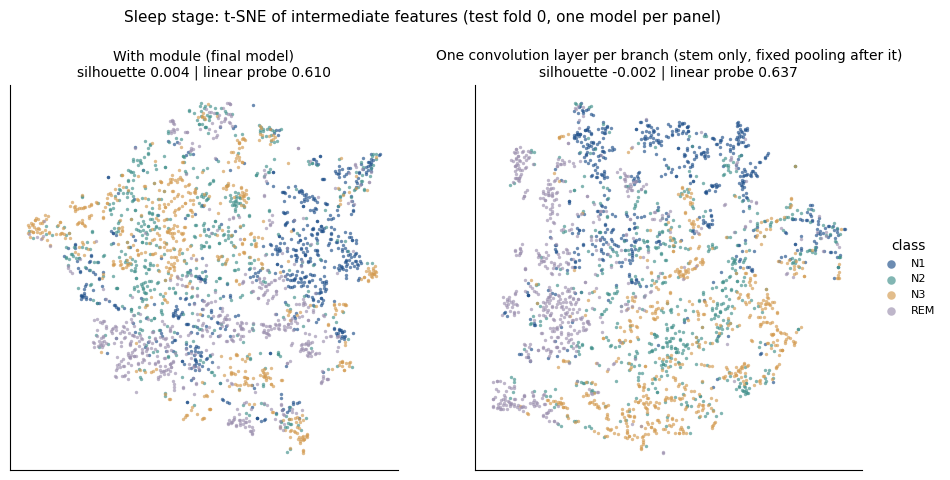

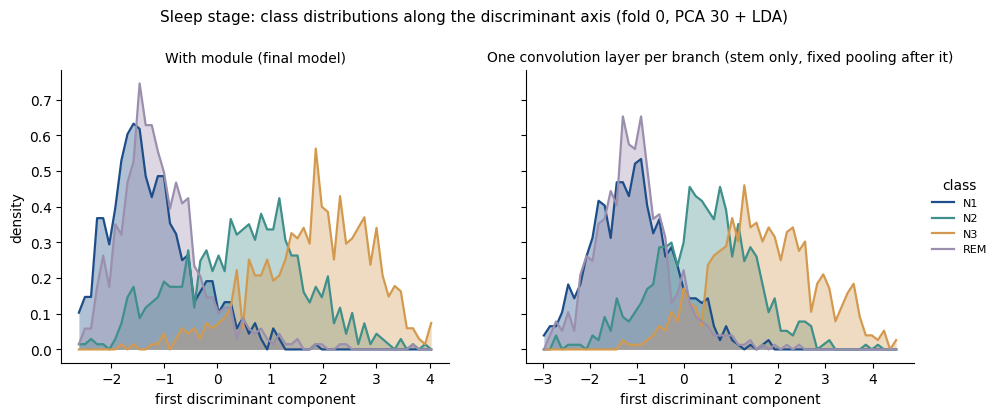

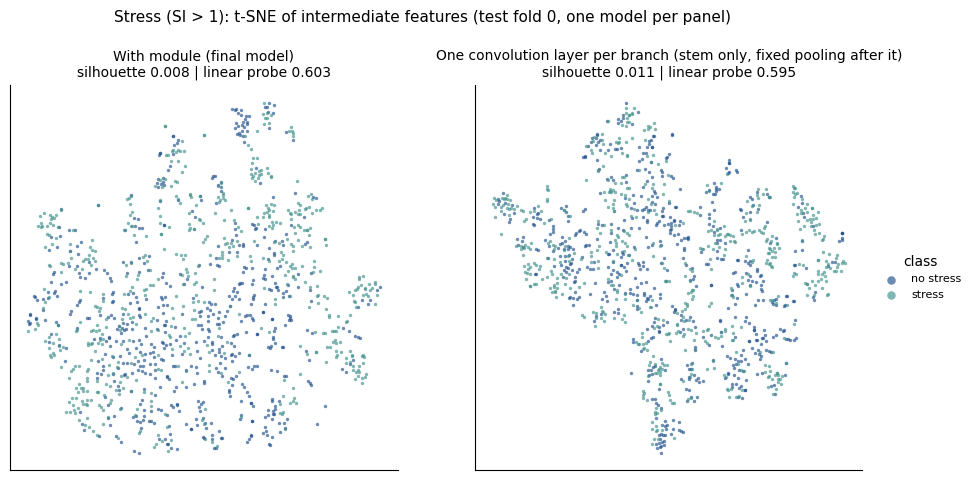

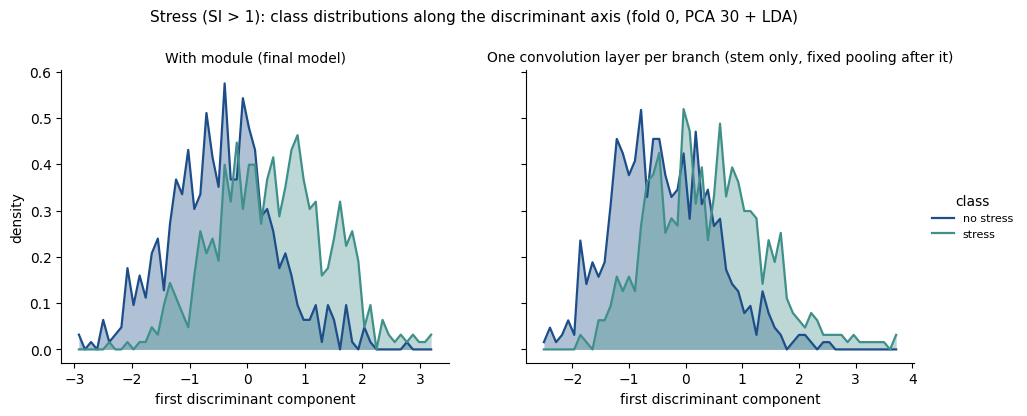

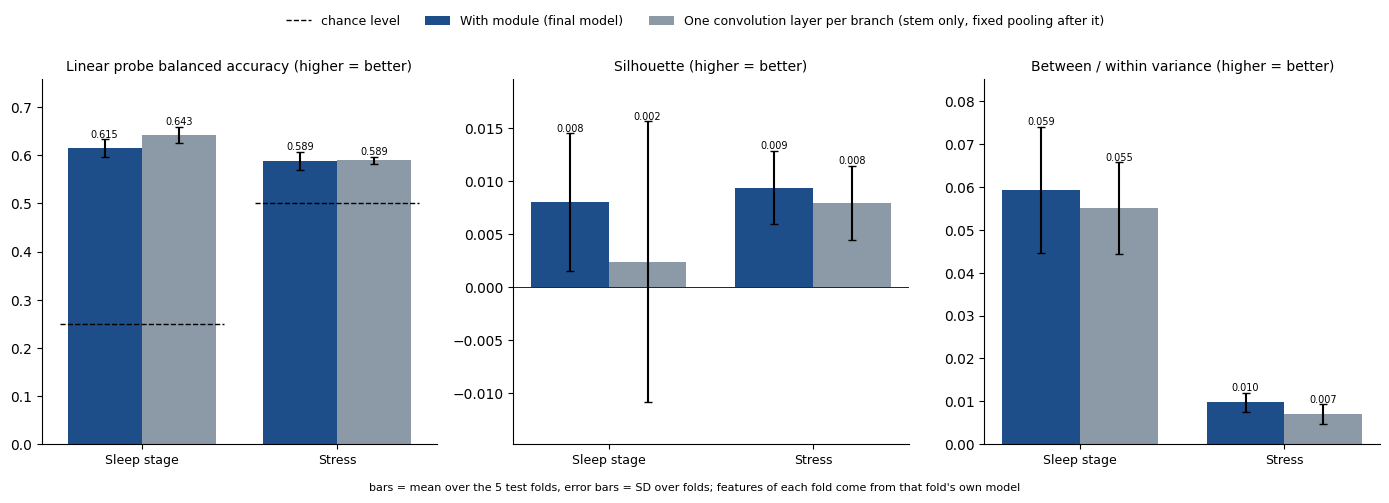

In [12]:
# Figures: t-SNE and LDA projection of one fold, separability bars with SD over the 5 folds
if HAVE_CKPT:
    NAVY, SLATE = "#1d4e89", "#8c99a6"
    CLS = ["#1d4e89", "#3f8f8a", "#d39a4f", "#9b8fae", "#b5546b", "#6f8f7e"]
    SHOW_FOLD = FOLDS[0]
    plt.rcParams.update({"savefig.dpi": 300, "savefig.bbox": "tight", "font.family": "DejaVu Sans", "font.size": 10,
                         "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})

    def embed(Z, perplexity):
        Z = StandardScaler().fit_transform(Z)
        Z = PCA(min(50, Z.shape[0] - 1, Z.shape[1]), random_state=0).fit_transform(Z)
        return TSNE(2, perplexity=perplexity, init="pca", random_state=0).fit_transform(Z)

    def fold_row(task, tag, k, key="v"):
        return SEP_FOLD[(SEP_FOLD.task == task) & (SEP_FOLD.model == tag) & (SEP_FOLD.features == key) & (SEP_FOLD.fold == k)].iloc[0]

    def mean_row(task, tag, key="v"):
        return SEP[(SEP.task == task) & (SEP.model == tag) & (SEP.features == key)].iloc[0]

    for task, (y_all, names) in TASKS.items():
        pk = PICK[(task, SHOW_FOLD)]; y = y_all[J[pk]]
        fig, axes = plt.subplots(1, 2, figsize=(11, 5))
        for ax, tag in zip(axes, ("with", "without")):
            E = embed(FEAT[(tag, "stress")]["v"][pk], 30)
            for c, n in enumerate(names):
                m = y == c
                ax.scatter(E[m, 0], E[m, 1], s=6, color=CLS[c % len(CLS)], alpha=.65, linewidths=0, label=n)
            r = fold_row(task, tag, SHOW_FOLD)
            ax.set_title(f"{LABEL[None if tag == 'with' else ABLATE]}\nsilhouette {r.silhouette:.3f} | linear probe {r.linear_probe_balanced_acc:.3f}", fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        axes[1].legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5), title="class")
        fig.suptitle(f"{task}: t-SNE of intermediate features (test fold {SHOW_FOLD}, one model per panel)", fontsize=11, y=1.03)
        fig.savefig(OUT / ("tsne_" + task.split()[0].lower() + ".png")); plt.show(); plt.close(fig)

        fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
        for ax, tag in zip(axes, ("with", "without")):
            Z = PCA(30, random_state=0).fit_transform(StandardScaler().fit_transform(FEAT[(tag, "stress")]["v"][pk]))
            ld = LinearDiscriminantAnalysis(n_components=1).fit_transform(Z, y)[:, 0]
            bins = np.linspace(np.percentile(ld, 0.5), np.percentile(ld, 99.5), 60)
            for c, n in enumerate(names):
                h, e = np.histogram(ld[y == c], bins=bins, density=True)
                ax.fill_between((e[1:] + e[:-1]) / 2, h, color=CLS[c % len(CLS)], alpha=.35, linewidth=0)
                ax.plot((e[1:] + e[:-1]) / 2, h, color=CLS[c % len(CLS)], lw=1.6, label=n)
            ax.set_title(LABEL[None if tag == "with" else ABLATE], fontsize=10); ax.set_xlabel("first discriminant component")
        axes[0].set_ylabel("density")
        axes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5), title="class")
        fig.suptitle(f"{task}: class distributions along the discriminant axis (fold {SHOW_FOLD}, PCA 30 + LDA)", fontsize=11, y=1.04)
        fig.savefig(OUT / ("lda_" + task.split()[0].lower() + ".png")); plt.show(); plt.close(fig)

    tasks = list(TASKS)
    chance = {"Sleep stage": 0.25, "Stress (SI > 1)": 0.5}
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
    for ax, (col, title) in zip(axes, (("linear_probe_balanced_acc", "Linear probe balanced accuracy (higher = better)"), ("silhouette", "Silhouette (higher = better)"), ("fisher_ratio", "Between / within variance (higher = better)"))):
        x = np.arange(len(tasks)); w = .38
        for o, (tag, color) in enumerate((("with", NAVY), ("without", SLATE))):
            vals = [mean_row(t, tag)[col] for t in tasks]; sds = [mean_row(t, tag)[col + "_sd"] for t in tasks]
            bars = ax.bar(x + (o - .5) * w, vals, w, yerr=sds, capsize=3, color=color, label=LABEL[None if tag == "with" else ABLATE])
            for b_, v, s_ in zip(bars, vals, sds):
                ax.text(b_.get_x() + b_.get_width() / 2, v + (s_ if v >= 0 else -s_), f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=7)
        if col == "linear_probe_balanced_acc":
            for xi, t in enumerate(tasks):
                ax.plot([xi - .42, xi + .42], [chance[t]] * 2, color="k", lw=1, ls="--", label="chance level" if xi == 0 else None)
        ax.axhline(0, color="k", lw=0.6)
        ax.margins(y=0.15)
        ax.set_xticks(x, [t.replace(" (SI > 1)", "") for t in tasks], fontsize=9)
        ax.set_title(title, fontsize=10)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 1.04))
    fig.text(0.5, -0.02, "bars = mean over the 5 test folds, error bars = SD over folds; features of each fold come from that fold's own model", ha="center", fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(OUT / "separability_bars.png"); plt.show(); plt.close(fig)
else:
    print("skipped: needs the checkpoints of pmrt_mt3_cv5 and of the ablated model")

mean (SD) over the 5 test folds; same windows, same folds, same measures for every source

Sleep stage
                                     silhouette davies_bouldin (lower = better)   fisher_ratio linear_probe_balanced_acc
raw signal                       -0.075 (0.012)                  31.129 (1.118)  0.001 (0.000)             0.263 (0.014)
band power (classical)            0.038 (0.002)                   3.425 (0.338)  0.230 (0.028)             0.638 (0.017)
learned features, ablated model   0.002 (0.013)                   5.078 (0.325)  0.055 (0.011)             0.643 (0.017)
learned features, with module     0.008 (0.007)                   5.887 (0.572)  0.059 (0.015)             0.615 (0.019)

Stress (SI > 1)
                                    silhouette davies_bouldin (lower = better)   fisher_ratio linear_probe_balanced_acc
raw signal                       0.002 (0.002)                  30.578 (2.000)  0.001 (0.000)             0.480 (0.034)
band power (classical)           0.

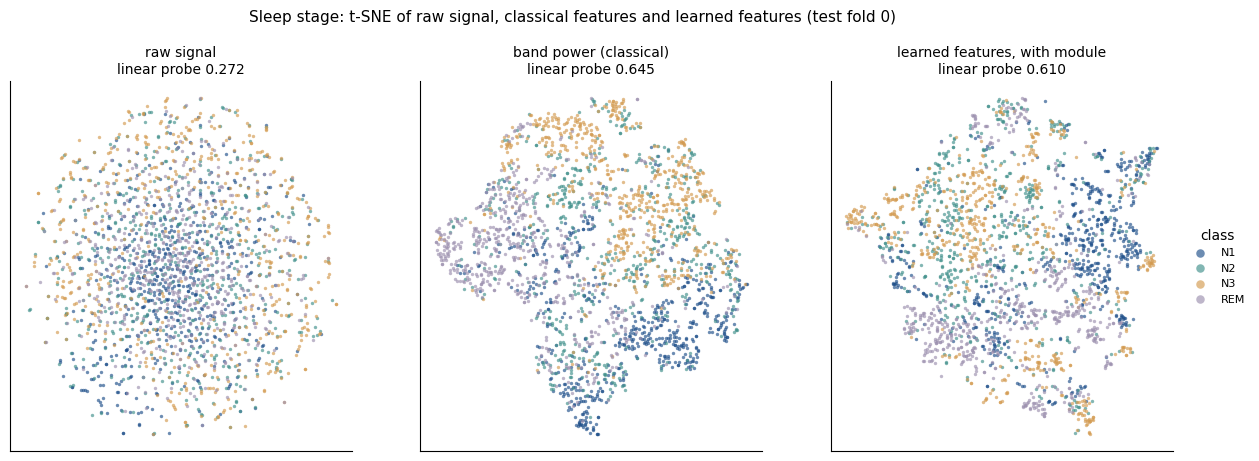

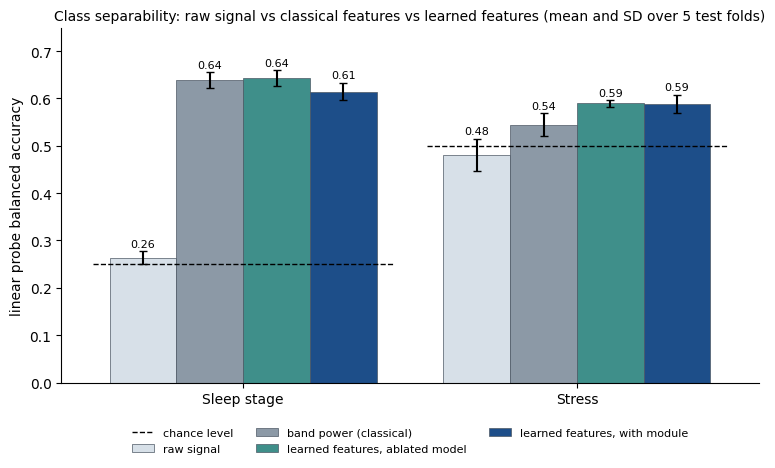

In [13]:
# Learned features versus raw signal and classical band-power features (same windows, same folds, same separability measures)
if HAVE_CKPT:
    from scipy.signal import welch
    EEG_BANDS = [(0.5, 4), (4, 8), (8, 12), (12, 16), (16, 30)]
    EMG_BANDS = [(10, 30), (30, 60)]

    def band_power(W):
        out = []
        for ch, bands in ((0, EEG_BANDS), (1, EMG_BANDS)):
            f, p = welch(W[:, ch, :].astype(np.float32), fs=125, nperseg=256, axis=-1)
            out += [np.log10(p[:, (f >= lo) & (f < hi)].sum(1) + 1e-12) for lo, hi in bands]
        out += [np.log10(W[:, ch, :].astype(np.float32).std(1) + 1e-6) for ch in (0, 1)]
        return np.stack(out, 1)

    SOURCES = {"raw signal": lambda pk: X[J[pk]].reshape(len(pk), -1).astype(np.float32),
               "band power (classical)": lambda pk: band_power(X[J[pk]]),
               "learned features, ablated model": lambda pk: FEAT[("without", "stress")]["v"][pk],
               "learned features, with module": lambda pk: FEAT[("with", "stress")]["v"][pk]}
    rows_raw = []
    for k in FOLDS:
        for task, (y_all, names) in TASKS.items():
            pk = PICK[(task, k)]
            for src, get in SOURCES.items():
                rows_raw.append({"fold": k, "task": task, "source": src, **separability(get(pk), y_all[J[pk]], REC[J[pk]])})
    RAW_FOLD = pd.DataFrame(rows_raw)
    keys = ["task", "source"]
    RAW = RAW_FOLD.groupby(keys)[METRICS].mean().reset_index().merge(RAW_FOLD.groupby(keys)[METRICS].std().add_suffix("_sd").reset_index(), on=keys)
    RAW.round(4).to_csv(OUT / "raw_vs_learned_features.csv", index=False)
    RAW_FOLD.round(4).to_csv(OUT / "raw_vs_learned_features_per_fold.csv", index=False)
    order = list(SOURCES)
    print("mean (SD) over the 5 test folds; same windows, same folds, same measures for every source\n")
    for task in TASKS:
        sub = RAW[RAW.task == task].set_index("source").loc[order]
        show = pd.DataFrame({m: [f"{a:.3f} ({b:.3f})" for a, b in zip(sub[m], sub[m + "_sd"])] for m in METRICS}, index=order)
        print(task); print(show.to_string()); print()

    def embed2(Z, perplexity=30):
        Z = StandardScaler().fit_transform(Z)
        Z = PCA(min(50, Z.shape[0] - 1, Z.shape[1]), random_state=0).fit_transform(Z)
        return TSNE(2, perplexity=perplexity, init="pca", random_state=0).fit_transform(Z)

    SHOW = FOLDS[0]
    task = "Sleep stage"
    y_all, names = TASKS[task]
    pk = PICK[(task, SHOW)]
    y = y_all[J[pk]]
    shown = ["raw signal", "band power (classical)", "learned features, with module"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, src in zip(axes, shown):
        E = embed2(SOURCES[src](pk))
        for c, n in enumerate(names):
            m = y == c
            ax.scatter(E[m, 0], E[m, 1], s=6, color=CLS[c % len(CLS)], alpha=.65, linewidths=0, label=n)
        r = RAW_FOLD[(RAW_FOLD.task == task) & (RAW_FOLD.source == src) & (RAW_FOLD.fold == SHOW)].iloc[0]
        ax.set_title(f"{src}\nlinear probe {r.linear_probe_balanced_acc:.3f}", fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    axes[-1].legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5), title="class")
    fig.suptitle(f"{task}: t-SNE of raw signal, classical features and learned features (test fold {SHOW})", fontsize=11, y=1.03)
    fig.savefig(OUT / "tsne_raw_vs_learned.png"); plt.show(); plt.close(fig)

    chance = {"Sleep stage": 0.25, "Stress (SI > 1)": 0.5}
    tasks = list(TASKS)
    colors = ["#d7e0e8", "#8c99a6", "#3f8f8a", "#1d4e89"]
    fig, ax = plt.subplots(figsize=(9, 4.6))
    w = 0.2
    for o, (src, color) in enumerate(zip(order, colors)):
        sub = RAW[RAW.source == src].set_index("task").loc[tasks]
        vals, sds = sub["linear_probe_balanced_acc"].to_numpy(), sub["linear_probe_balanced_acc_sd"].to_numpy()
        bars = ax.bar(np.arange(len(tasks)) + (o - 1.5) * w, vals, w, yerr=sds, capsize=3, color=color, edgecolor="#4d5864", linewidth=0.5, label=src)
        for b_, v, s_ in zip(bars, vals, sds):
            ax.text(b_.get_x() + b_.get_width() / 2, v + s_ + 0.005, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    for xi, t in enumerate(tasks):
        ax.plot([xi - 0.45, xi + 0.45], [chance[t]] * 2, color="k", lw=1, ls="--", label="chance level" if xi == 0 else None)
    ax.set_xticks(np.arange(len(tasks)), [t.replace(" (SI > 1)", "") for t in tasks])
    ax.set_ylabel("linear probe balanced accuracy")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
    ax.set_title("Class separability: raw signal vs classical features vs learned features (mean and SD over 5 test folds)", fontsize=10)
    fig.savefig(OUT / "probe_raw_vs_learned.png"); plt.show(); plt.close(fig)
else:
    print("skipped: needs the checkpoints of pmrt_mt3_cv5 and of the ablated model")

test subjects per class in each fold (a class needs at least 2 subjects in the fold to be used)

Disorder (6 classes)
 fold  Healthy  NFLE  RBD  PLM  Insomnia  Narcolepsy  classes kept  probe splits
    0        2     8    4    2         2           1             5             2
    1        2     8    4    2         2           1             5             2
    2        3     7    5    2         2           1             5             2
    3        3     7    5    2         2           1             5             2
    4        3     8    4    2         1           1             4             2

Healthy vs disorder
 fold  Healthy  classes kept  probe splits  disorder
    0        2             2             2        17
    1        2             2             2        17
    2        3             2             3        17
    3        3             2             3        17
    4        3             2             3        16

mean (SD) over the test folds that could be used; the pr

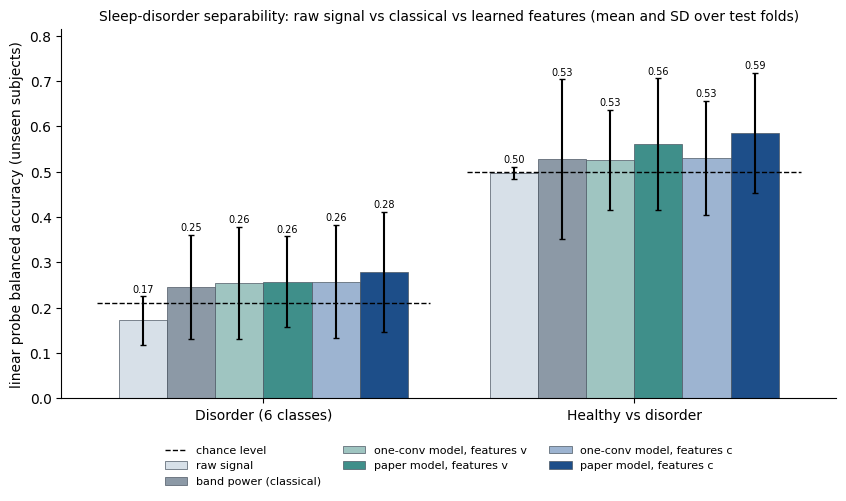

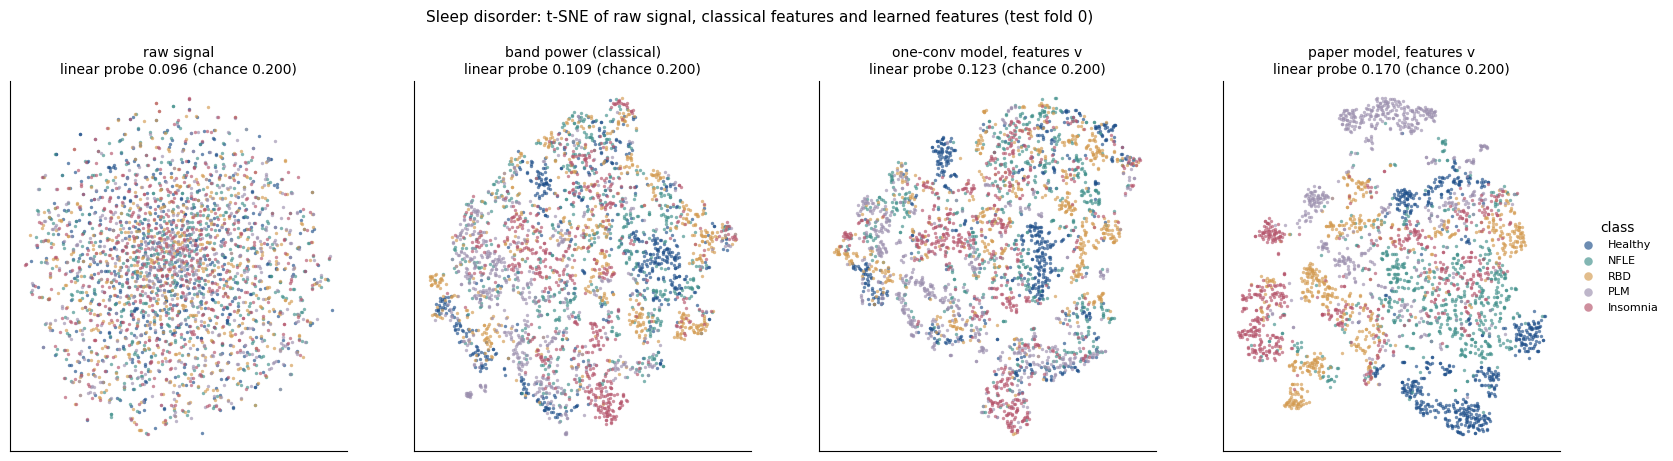

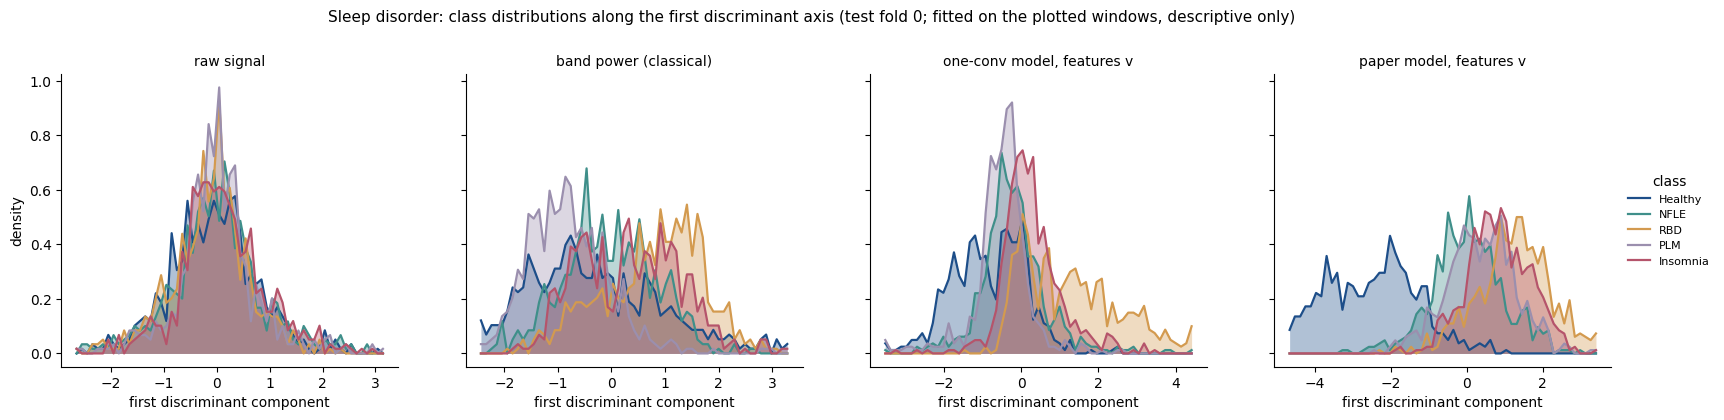

In [14]:
# Sleep-disorder class separability of raw signal, band power and learned features (paper model and ablated model), probed on unseen subjects
if HAVE_CKPT:
    from sklearn.model_selection import StratifiedGroupKFold
    assert (FEAT[("with", "dis")]["j"] == J).all() and (FEAT[("without", "dis")]["j"] == J).all()
    YD, RD = DIS[J], REC[J]
    ALAB = {"singleconv": "single-conv model", "oneconv": "one-conv model"}.get(ABLATE, "ablated model")
    DTASKS = {"Disorder (6 classes)": (YD, list(M.DISORDERS)), "Healthy vs disorder": ((YD > 0).astype(int), ["Healthy", "disorder"])}
    CAP_DIS, MIN_SUBJECTS = 600, 2

    def pick_by_subject(pos, y, cap, seed):
        rng = np.random.default_rng(seed); out = []
        for c in np.unique(y[pos]):
            pc = pos[y[pos] == c]; subs = np.unique(RD[pc]); per = max(1, cap // len(subs))
            out += [rng.permutation(pc[RD[pc] == s])[:per] for s in subs]
        return np.sort(np.concatenate(out))

    def separability_subjects(Z, y, groups, n_splits):
        Z = StandardScaler().fit_transform(Z)
        pred = np.zeros(len(y), int)
        for a, b in StratifiedGroupKFold(n_splits, shuffle=True, random_state=0).split(Z, y, groups):
            clf = LogisticRegression(max_iter=300, C=0.1, class_weight="balanced").fit(Z[a], y[a])
            pred[b] = clf.predict(Z[b])
        return {"silhouette": silhouette_score(Z, y), "davies_bouldin (lower = better)": davies_bouldin_score(Z, y),
                "fisher_ratio": fisher_ratio(Z, y), "linear_probe_balanced_acc": balanced_accuracy_score(y, pred)}

    DSRC = {"raw signal": lambda pk: X[J[pk]].reshape(len(pk), -1).astype(np.float32),
            "band power (classical)": lambda pk: band_power(X[J[pk]]),
            f"{ALAB}, features v": lambda pk: FEAT[("without", "dis")]["v"][pk],
            "paper model, features v": lambda pk: FEAT[("with", "dis")]["v"][pk],
            f"{ALAB}, features c": lambda pk: FEAT[("without", "dis")]["c"][pk],
            "paper model, features c": lambda pk: FEAT[("with", "dis")]["c"][pk]}
    dorder = list(DSRC)
    DPICK, info_rows, sep_rows = {}, [], []
    for k in FOLDS:
        mk = np.where(FK == k)[0]
        mk = mk[YD[mk] != M.IGNORE]
        for task, (y_all, names) in DTASKS.items():
            nsub = pd.Series(RD[mk]).groupby(y_all[mk]).nunique()
            keep = nsub.index[nsub >= MIN_SUBJECTS].to_numpy()
            n_splits = int(min(5, nsub[keep].min())) if len(keep) >= 2 else 0
            info_rows.append({"fold": k, "task": task, **{n: int(nsub.get(c, 0)) for c, n in enumerate(names)}, "classes kept": len(keep), "probe splits": n_splits})
            if n_splits < 2:
                continue
            pk = pick_by_subject(mk[np.isin(y_all[mk], keep)], y_all, CAP_DIS, k)
            DPICK[(task, k)] = pk
            for src, get in DSRC.items():
                sep_rows.append({"fold": k, "task": task, "source": src, "chance": 1 / len(keep),
                                 **separability_subjects(get(pk), y_all[pk], RD[pk], n_splits)})
    DIS_INFO, DIS_FOLD = pd.DataFrame(info_rows), pd.DataFrame(sep_rows)
    dkeys = ["task", "source"]
    DIS_SEP = DIS_FOLD.groupby(dkeys)[METRICS + ["chance"]].mean().reset_index().merge(DIS_FOLD.groupby(dkeys)[METRICS].std().add_suffix("_sd").reset_index(), on=dkeys)
    DIS_SEP.round(4).to_csv(OUT / "disorder_separability.csv", index=False)
    DIS_FOLD.round(4).to_csv(OUT / "disorder_separability_per_fold.csv", index=False)
    DIS_INFO.to_csv(OUT / "disorder_subjects_per_class_per_fold.csv", index=False)
    print("test subjects per class in each fold (a class needs at least", MIN_SUBJECTS, "subjects in the fold to be used)\n")
    for task in DTASKS:
        print(task); print(DIS_INFO[DIS_INFO.task == task].drop(columns="task").dropna(axis=1, how="all").astype(int).to_string(index=False)); print()
    print("mean (SD) over the test folds that could be used; the probe is trained and tested on different subjects; learned features come from best_dis.pt of the same fold\n")
    for task in DTASKS:
        sub = DIS_SEP[DIS_SEP.task == task].set_index("source").loc[dorder]
        show = pd.DataFrame({m: [f"{a:.3f} ({b:.3f})" for a, b in zip(sub[m], sub[m + "_sd"])] for m in METRICS}, index=dorder)
        print(f"{task} | folds used: {DIS_FOLD[DIS_FOLD.task == task].fold.nunique()} | chance level of the probe: {sub['chance'].iloc[0]:.3f}")
        print(show.to_string()); print()
    print("paired difference (paper model - " + ALAB + ") over the folds used:")
    for task in DTASKS:
        for key in ("v", "c"):
            w = DIS_FOLD[(DIS_FOLD.task == task) & (DIS_FOLD.source == f"paper model, features {key}")].set_index("fold")
            o = DIS_FOLD[(DIS_FOLD.task == task) & (DIS_FOLD.source == f"{ALAB}, features {key}")].set_index("fold")
            for m in ("linear_probe_balanced_acc", "silhouette", "fisher_ratio"):
                d = w[m] - o[m]
                print(f"  {task:22s} features {key} {m:26s} mean diff {d.mean():+.4f} | folds where paper model > {ALAB}: {int((d > 0).sum())}/{len(d)}")

    colors = ["#d7e0e8", "#8c99a6", "#9fc5c1", "#3f8f8a", "#9db4d1", "#1d4e89"]
    tasks = list(DTASKS)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    w = 0.13
    for o, (src, color) in enumerate(zip(dorder, colors)):
        sub = DIS_SEP[DIS_SEP.source == src].set_index("task").loc[tasks]
        vals, sds = sub["linear_probe_balanced_acc"].to_numpy(), sub["linear_probe_balanced_acc_sd"].to_numpy()
        bars = ax.bar(np.arange(len(tasks)) + (o - 2.5) * w, vals, w, yerr=sds, capsize=2, color=color, edgecolor="#4d5864", linewidth=0.5, label=src)
        for b_, v, s_ in zip(bars, vals, sds):
            ax.text(b_.get_x() + b_.get_width() / 2, v + s_ + 0.005, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
    for xi, t in enumerate(tasks):
        ax.plot([xi - 0.45, xi + 0.45], [DIS_SEP[DIS_SEP.task == t].chance.iloc[0]] * 2, color="k", lw=1, ls="--", label="chance level" if xi == 0 else None)
    ax.set_xticks(np.arange(len(tasks)), tasks)
    ax.set_ylabel("linear probe balanced accuracy (unseen subjects)")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
    ax.set_title("Sleep-disorder separability: raw signal vs classical vs learned features (mean and SD over test folds)", fontsize=10)
    fig.savefig(OUT / "probe_disorder_sources.png"); plt.show(); plt.close(fig)

    def embed_d(Z, perplexity=30):
        Z = StandardScaler().fit_transform(Z)
        Z = PCA(min(50, Z.shape[0] - 1, Z.shape[1]), random_state=0).fit_transform(Z)
        return TSNE(2, perplexity=perplexity, init="pca", random_state=0).fit_transform(Z)

    task = "Disorder (6 classes)"
    SHOW_D = DIS_INFO[DIS_INFO.task == task].sort_values(["classes kept", "fold"], ascending=[False, True]).fold.iloc[0]
    if (task, SHOW_D) in DPICK:
        pk = DPICK[(task, SHOW_D)]
        y, names = DTASKS[task][0][pk], DTASKS[task][1]
        shown = ["raw signal", "band power (classical)", f"{ALAB}, features v", "paper model, features v"]
        fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
        for ax, src in zip(axes, shown):
            E = embed_d(DSRC[src](pk))
            for c, n in enumerate(names):
                m = y == c
                if m.any():
                    ax.scatter(E[m, 0], E[m, 1], s=6, color=CLS[c % len(CLS)], alpha=.65, linewidths=0, label=n)
            r = DIS_FOLD[(DIS_FOLD.task == task) & (DIS_FOLD.source == src) & (DIS_FOLD.fold == SHOW_D)].iloc[0]
            ax.set_title(f"{src}\nlinear probe {r.linear_probe_balanced_acc:.3f} (chance {r.chance:.3f})", fontsize=10)
            ax.set_xticks([]); ax.set_yticks([])
        axes[-1].legend(markerscale=2.5, fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5), title="class")
        fig.suptitle(f"Sleep disorder: t-SNE of raw signal, classical features and learned features (test fold {SHOW_D})", fontsize=11, y=1.03)
        fig.savefig(OUT / "tsne_disorder_sources.png"); plt.show(); plt.close(fig)

        from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
        fig, axes = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
        for ax, src in zip(axes, shown):
            Z0 = StandardScaler().fit_transform(DSRC[src](pk))
            Z = PCA(min(30, Z0.shape[0] - 1, Z0.shape[1]), random_state=0).fit_transform(Z0)
            ld = LinearDiscriminantAnalysis(n_components=1).fit_transform(Z, y)[:, 0]
            bins = np.linspace(np.percentile(ld, 0.5), np.percentile(ld, 99.5), 60)
            for c, n in enumerate(names):
                if (y == c).any():
                    h, e = np.histogram(ld[y == c], bins=bins, density=True)
                    ax.fill_between((e[1:] + e[:-1]) / 2, h, color=CLS[c % len(CLS)], alpha=.35, linewidth=0)
                    ax.plot((e[1:] + e[:-1]) / 2, h, color=CLS[c % len(CLS)], lw=1.6, label=n)
            ax.set_title(src, fontsize=10); ax.set_xlabel("first discriminant component")
        axes[0].set_ylabel("density")
        axes[-1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5), title="class")
        fig.suptitle(f"Sleep disorder: class distributions along the first discriminant axis (test fold {SHOW_D}; fitted on the plotted windows, descriptive only)", fontsize=11, y=1.05)
        fig.savefig(OUT / "lda_disorder_sources.png"); plt.show(); plt.close(fig)
else:
    print("skipped: needs the checkpoints of pmrt_mt3_cv5 and of the ablated model")

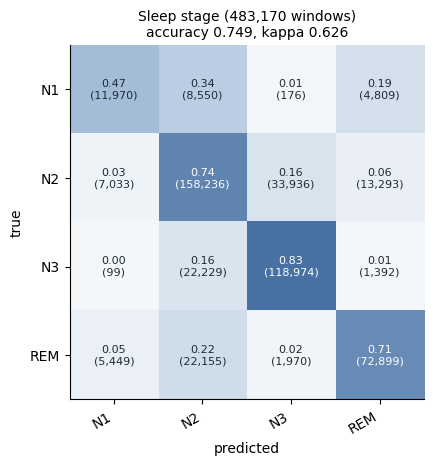

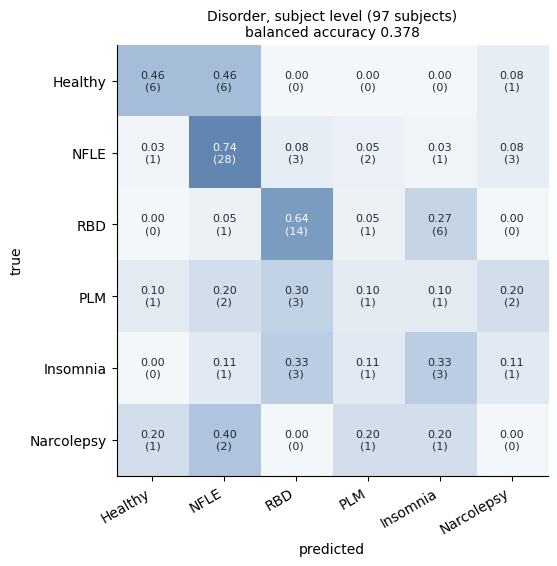

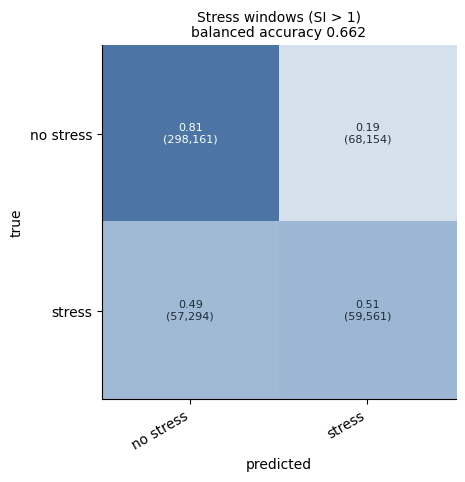

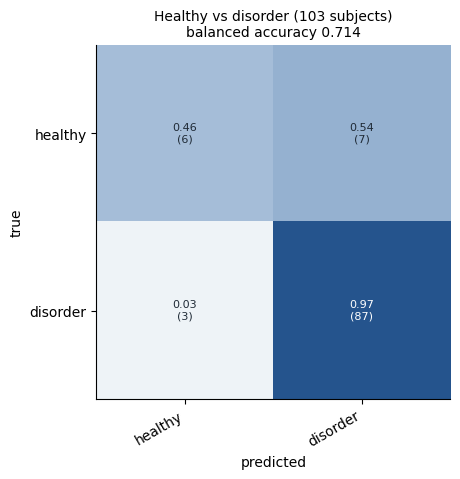

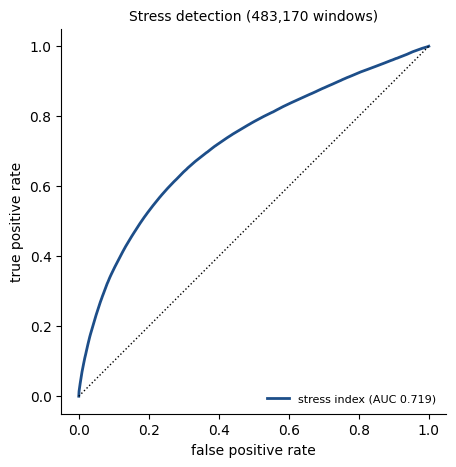

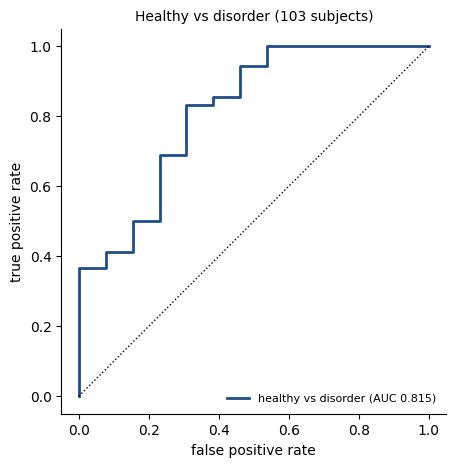

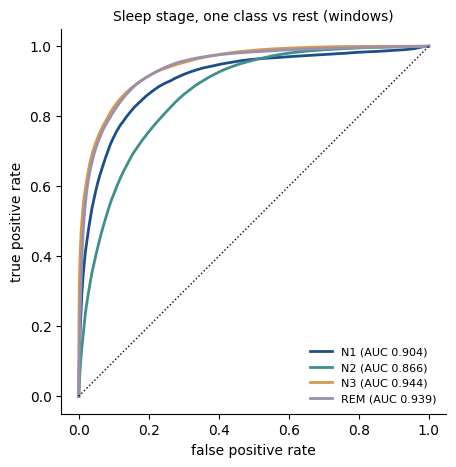

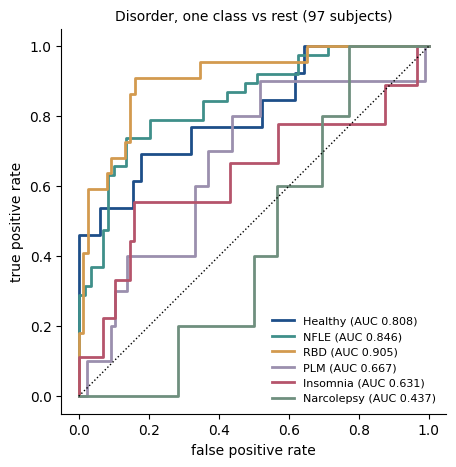

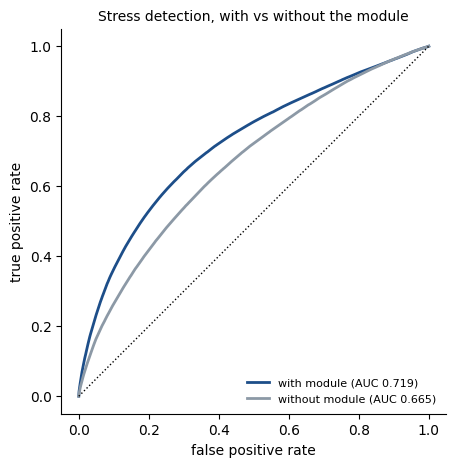

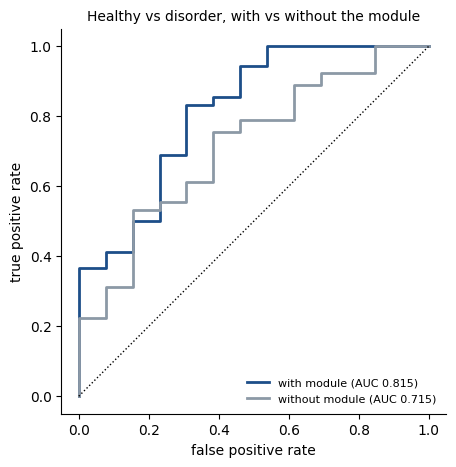

In [15]:
# Confusion matrices and ROC curves of the final model (plus ROC with vs without the module)
if HAVE_PRED:
    from matplotlib.colors import LinearSegmentedColormap
    from sklearn.metrics import confusion_matrix, roc_curve
    CMAP = LinearSegmentedColormap.from_list("b", ["#f4f7fa", "#9fb9d6", NAVY])
    P, S = P_with, S_with
    S6 = S[S.dis >= 0]
    sp, dp = P.stg_pred.to_numpy(), S6[PC].to_numpy().argmax(1)
    ys, ps = P.y_stress, (P.si_pred > 1).astype(int)
    hb = (S.group != "Healthy").astype(int); hp = (S[PC].to_numpy().argmax(1) != 0).astype(int)

    def cm_fig(cm, labels, title, name):
        p = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(5.6 if len(labels) > 4 else 4.6,) * 2); ax.imshow(p, cmap=CMAP, vmin=0, vmax=1)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, f"{p[i, j]:.2f}\n({int(cm[i, j]):,})", ha="center", va="center", fontsize=8, color="white" if p[i, j] > .55 else "#1f2a36")
        ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right"); ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=10); fig.savefig(OUT / f"{name}.png"); plt.show(); plt.close(fig)

    cm_fig(confusion_matrix(P.stg, sp, labels=range(4)), M.STAGES, f"Sleep stage ({len(P):,} windows)\naccuracy {r_with['Stage accuracy']:.3f}, kappa {r_with['Stage kappa']:.3f}", "cm_sleep_stage")
    cm_fig(confusion_matrix(S6.dis, dp, labels=range(6)), M.DISORDERS, f"Disorder, subject level ({len(S6)} subjects)\nbalanced accuracy {r_with['Disorder balanced acc (6 classes, subject level)']:.3f}", "cm_disorder")
    cm_fig(confusion_matrix(ys, ps, labels=[0, 1]), ["no stress", "stress"], f"Stress windows (SI > 1)\nbalanced accuracy {balanced_accuracy_score(ys, ps):.3f}", "cm_stress")
    cm_fig(confusion_matrix(hb, hp, labels=[0, 1]), ["healthy", "disorder"], f"Healthy vs disorder ({len(S)} subjects)\nbalanced accuracy {balanced_accuracy_score(hb, hp):.3f}", "cm_healthy_vs_disorder")

    def roc_fig(curves, title, name):
        fig, ax = plt.subplots(figsize=(5.2, 5.0))
        for lab, y, s, c in curves:
            f, t, _ = roc_curve(y, s); k = np.linspace(0, len(f) - 1, min(len(f), 600)).astype(int)
            ax.plot(f[k], t[k], color=c, lw=2, label=f"{lab} (AUC {roc_auc_score(y, s):.3f})")
        ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.set_aspect("equal")
        ax.set_title(title, fontsize=10); ax.legend(fontsize=8, loc="lower right"); fig.savefig(OUT / f"{name}.png"); plt.show(); plt.close(fig)

    roc_fig([("stress index", ys, P.si_pred, NAVY)], f"Stress detection ({len(P):,} windows)", "roc_stress")
    roc_fig([("healthy vs disorder", hb, 1 - S.p_Healthy, NAVY)], f"Healthy vs disorder ({len(S)} subjects)", "roc_healthy_vs_disorder")
    roc_fig([(s, (P.stg == i).astype(int), P[f"p_{s}"], CLS[i]) for i, s in enumerate(M.STAGES)], "Sleep stage, one class vs rest (windows)", "roc_sleep_stage_per_class")
    roc_fig([(c, (S6.dis == i).astype(int), S6[f"p_{c}"], CLS[i]) for i, c in enumerate(M.DISORDERS)], f"Disorder, one class vs rest ({len(S6)} subjects)", "roc_disorder_per_class")
    Q, SQ = P_without, S_without
    roc_fig([("with module", ys, P.si_pred, NAVY), ("without module", Q.y_stress, Q.si_pred, SLATE)], "Stress detection, with vs without the module", "roc_stress_with_vs_without")
    roc_fig([("with module", hb, 1 - S.p_Healthy, NAVY), ("without module", (SQ.group != "Healthy").astype(int), 1 - SQ.p_Healthy, SLATE)], "Healthy vs disorder, with vs without the module", "roc_healthy_vs_disorder_with_vs_without")
else:
    print("skipped: needs the finished run pmrt_mt3_cv5 and all folds of the ablated model")


In [16]:
# Save numbers, build the zip of figures and tables
if HAVE_PRED:
    summary = {"ablate": ABLATE, "folds": FOLDS, "metrics": tab.round(4).to_dict(),
               "stage_auc_per_class": {s: roc_auc_score((P.stg == i).astype(int), P[f"p_{s}"]) for i, s in enumerate(M.STAGES)},
               "disorder_auc_per_class": {c: roc_auc_score((S6.dis == i).astype(int), S6[f"p_{c}"]) for i, c in enumerate(M.DISORDERS) if (S6.dis == i).any()},
               "cm_stage": confusion_matrix(P.stg, sp, labels=range(4)).tolist(), "cm_disorder": confusion_matrix(S6.dis, dp, labels=range(6)).tolist(),
               "cm_stress": confusion_matrix(ys, ps, labels=[0, 1]).tolist(), "cm_healthy_vs_disorder": confusion_matrix(hb, hp, labels=[0, 1]).tolist()}
    if HAVE_CKPT: summary["separability"] = SEP.round(4).to_dict("records")
    (OUT / "report_numbers.json").write_text(json.dumps(summary, indent=1, default=float))
zip_path = shutil.make_archive(str(ROOT / f"ablation_analysis_{ABLATE}"), "zip", OUT)
print("saved", zip_path, "|", len(list(OUT.glob("*.png"))), "figures")
print("download:", Path(zip_run).name, "(trained model without the module) and", Path(zip_path).name, "(figures and tables)")


saved /content/drive/MyDrive/sleep_project/ablation_analysis_oneconv.zip | 20 figures
download: ablation_run_oneconv.zip (trained model without the module) and ablation_analysis_oneconv.zip (figures and tables)
